# 10: Muon-catalysed fusion as a neutron source for a subcritical fission blanket

Notebook 09 found pure muon-catalysed fusion (μCF) ~9× short of net electricity. Each d–t fusion also emits a **14.1 MeV neutron**. In a *subcritical* fission blanket (k_eff < 1, so the chain dies out unless the source keeps feeding it), each source neutron triggers a short fission chain worth ~1–4 GeV. This notebook asks:

1. How much does a blanket raise the gain, and at what k_eff does μCF reach net electricity with **today's** numbers?
2. **The honest benchmark:** accelerator-driven systems (ADS, e.g. MYRRHA) already drive subcritical blankets with **spallation** neutrons from ~1 GeV protons. Does a μCF source beat spallation per GeV of beam?
3. Can the blanket also breed the tritium the d–t fuel consumes?

**Inputs:** μCF numbers from notebook 09 (150 fusions per muon, 5 GeV per muon, levers). Spallation yield ~20–35 neutrons per 1 GeV proton on lead (GEANT4 studies, IPAC 2016; standard range, abstract-level). Fission: ν ≈ 2.5 neutrons and ~200 MeV per fission (standard). Subcritical source multiplication: fissions per source neutron = k/(ν(1−k)). Efficiencies η_th = 0.4, η_acc = 0.4 (as notebook 09).

In [1]:
import numpy as np, matplotlib.pyplot as plt
plt.rcParams.update({"axes.spines.top":False,"axes.spines.right":False,"axes.grid":True,
                     "grid.alpha":.25,"font.size":10,"axes.titlesize":11})
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, INK, MUTED = "#2a78d6","#eb6834","#1baf7a","#eda100","#e87ba4","#0b0b0b","#52514e"
NU, E_FIS = 2.5, 200.0              # neutrons and MeV per fission
E_DT = 17.59                        # MeV per d-t fusion
ETA_TH, ETA_ACC = 0.40, 0.40
SPALL = (20.0, 35.0)                # neutrons per GeV of proton beam on lead (range)

def fissions_per_source(k): return k/(NU*(1 - k))
def gain(n_per_GeV, k, fusion_MeV_per_n=0.0):
    # thermal energy out per GeV of beam, and electric gain (electricity out / wall-plug in)
    E_out = n_per_GeV*(fusion_MeV_per_n + fissions_per_source(k)*E_FIS)/1000.0   # GeV thermal per GeV beam
    return E_out, ETA_TH*ETA_ACC*E_out

sources = {
  "spallation ADS (20–35 n/GeV)": (27.5, 0.0),
  "μCF today (150 n per 5 GeV)": (150/5, E_DT),
  "μCF, muon cost /2.5 (150 n per 2 GeV)": (150/2, E_DT),
  "μCF, all levers (336 n per 2 GeV)": (336/2, E_DT),
}
print(f"{'source':40s} {'n/GeV':>6s}")
for name, (n, _) in sources.items():
    print(f"{name:40s} {n:6.0f}")
print(f"\nfissions per source neutron: k=0.90 -> {fissions_per_source(0.90):.1f},  k=0.95 -> {fissions_per_source(0.95):.1f},  k=0.98 -> {fissions_per_source(0.98):.1f}")

source                                    n/GeV
spallation ADS (20–35 n/GeV)                 28
μCF today (150 n per 5 GeV)                  30
μCF, muon cost /2.5 (150 n per 2 GeV)        75
μCF, all levers (336 n per 2 GeV)           168

fissions per source neutron: k=0.90 -> 3.6,  k=0.95 -> 7.6,  k=0.98 -> 19.6


## 1. Gain vs k_eff

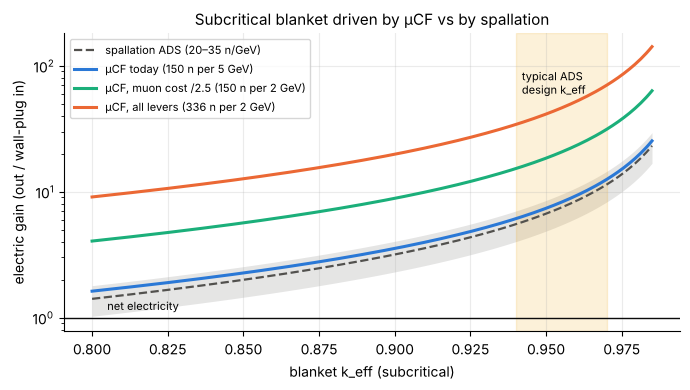

k_eff = 0.9: spallation ADS:   3.2  μCF today:   3.5  μCF, muon cost /2.5:   8.9  μCF, all levers:  19.8
k_eff = 0.95: spallation ADS:   6.7  μCF today:   7.4  μCF, muon cost /2.5:  18.5  μCF, all levers:  41.3
k_eff = 0.97: spallation ADS:  11.4  μCF today:  12.5  μCF, muon cost /2.5:  31.3  μCF, all levers:  70.0


In [2]:
ks = np.linspace(0.80, 0.985, 200)
fig, ax = plt.subplots(figsize=(7, 4))
cols = [MUTED, BLUE, AQUA, ORANGE]
for (name, (n, ef)), col in zip(sources.items(), cols):
    ax.plot(ks, [gain(n, k, ef)[1] for k in ks], color=col, lw=2.2 if "μCF" in name else 1.6,
            ls="-" if "μCF" in name else "--", label=name)
ax.fill_between(ks, [gain(SPALL[0], k)[1] for k in ks], [gain(SPALL[1], k)[1] for k in ks], color=MUTED, alpha=.15, lw=0)
ax.axhline(1, color=INK, lw=1); ax.text(0.805, 1.15, "net electricity", fontsize=8)
ax.axvspan(0.94, 0.97, color=YELLOW, alpha=.15); ax.text(0.942, 60, "typical ADS\ndesign k_eff", fontsize=8)
ax.set_yscale("log"); ax.set_xlabel("blanket k_eff (subcritical)"); ax.set_ylabel("electric gain (out / wall-plug in)")
ax.set_title("Subcritical blanket driven by μCF vs by spallation"); ax.legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.savefig("../figures/10_hybrid_gain.png", dpi=130); plt.show()
for k in [0.90, 0.95, 0.97]:
    row = "  ".join(f"{name.split(' (')[0]}: {gain(n, k, ef)[1]:5.1f}" for name, (n, ef) in sources.items())
    print(f"k_eff = {k}: {row}")

## 2. When does μCF beat spallation?

In [3]:
n_spall = np.array(SPALL)
X = 150
E_mu_break = X/n_spall            # GeV per muon at which μCF gives as many neutrons per GeV as spallation
print(f"With X = {X} fusions per muon, μCF matches spallation (20–35 n/GeV) at a muon cost of {E_mu_break[1]:.1f}–{E_mu_break[0]:.1f} GeV")
print(f"At today's 5 GeV per muon it needs X >= {5*n_spall[0]:.0f}–{5*n_spall[1]:.0f} fusions per muon")
k = 0.95
share = E_DT/(E_DT + fissions_per_source(k)*E_FIS)
print(f"At k_eff = {k}, the fusion energy itself is only {share*100:.1f}% of the thermal output; the blanket supplies the rest")

With X = 150 fusions per muon, μCF matches spallation (20–35 n/GeV) at a muon cost of 4.3–7.5 GeV
At today's 5 GeV per muon it needs X >= 100–175 fusions per muon
At k_eff = 0.95, the fusion energy itself is only 1.1% of the thermal output; the blanket supplies the rest


## 3. Tritium self-sufficiency

Each d–t fusion consumes one triton. A lithium-bearing blanket breeds tritium by neutron capture on ⁶Li. In a subcritical chain each source neutron gives 1/(1−k) neutrons in total, of which k/(ν(1−k)) are absorbed in fission. The rest are available for breeding, capture and leakage.

In [4]:
for k in [0.90, 0.95, 0.97]:
    total = 1/(1 - k); fis = fissions_per_source(k); spare = total - fis
    print(f"k_eff = {k}: {total:5.1f} neutrons per source neutron, {fis:5.1f} absorbed in fission, {spare:5.1f} left for breeding/capture/leakage")
print("-> even if most of the spare neutrons are lost, breeding 1 triton per fusion needs only ~1 of them: tritium self-sufficiency is not the constraint")

k_eff = 0.9:  10.0 neutrons per source neutron,   3.6 absorbed in fission,   6.4 left for breeding/capture/leakage
k_eff = 0.95:  20.0 neutrons per source neutron,   7.6 absorbed in fission,  12.4 left for breeding/capture/leakage
k_eff = 0.97:  33.3 neutrons per source neutron,  12.9 absorbed in fission,  20.4 left for breeding/capture/leakage
-> even if most of the spare neutrons are lost, breeding 1 triton per fusion needs only ~1 of them: tritium self-sufficiency is not the constraint


## 4. Verdict

* **A subcritical blanket closes μCF's energy gap with today's numbers.** At typical ADS designs (k_eff ≈ 0.95) the electric gain is several units (table above), versus 0.11 for pure μCF. The absolute gains here are optimistic, since the multiplication formula ignores (n,2n), parasitic capture and leakage, but the **comparison between sources** is robust: the same blanket multiplies every source's neutrons equally.
* **But that gain comes from fission, and spallation already delivers it.** At today's 5 GeV per muon, μCF gives ~30 neutrons per GeV of beam, **the same as spallation (20–35)**. A μCF-driven blanket only beats the proven ADS approach once muons are cheaper (below ~4–8 GeV at 150 fusions per muon) or catalyse more fusions (≳100–175 per muon at 5 GeV). With the notebook 09 levers (2 GeV/muon, ~336 fusions), μCF gives ~170 n/GeV, about **5–8× spallation**, and that's where the hybrid becomes genuinely interesting.
* **The fusion itself supplies only ~1% of the heat** at k_eff = 0.95. A μCF hybrid is a neutron-source technology, not a fusion power plant.
* **Tritium is not a constraint:** a subcritical blanket produces far more spare neutrons than the ~1 per fusion needed for breeding.
* **Trade-offs:** fission waste, licensing and subcritical-reactor safety (as for any ADS), plus tritium handling. The benefit over a critical reactor is the ADS one: the chain stops when the beam stops.

**So the muon gap is addressed in two ways:** directly (notebook 09: cheaper muons, lower sticking, faster cycling, better conversion), or via a blanket. In the blanket route μCF is worth pursuing only if it out-produces spallation, which needs the same muon-cost and sticking improvements. **Either way, muon cost and sticking are the numbers to watch.**

**Status:** spallation yield range from GEANT4 studies (abstract-level); ν and energy per fission standard; the subcritical multiplication formula ignores (n,2n), parasitic capture and leakage (it overstates fissions slightly). Efficiencies as in notebook 09.